### Inference and Ensembling
After training, you need to use the two models to find the encroachment zones. This script shows how to load an image, get predictions from both models, and combine them.

In [1]:
import torch
import cv2
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
import matplotlib.pyplot as plt

In [2]:
# --- Configuration ---
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
MODEL_VEG_PATH = '../models/vepl_vegetation_model.pth.tar'
MODEL_PL_PATH = '../models/vepl_powerline_model.pth.tar'
IMAGE_HEIGHT = 256
IMAGE_WIDTH = 256

# --- Load Models ---
def load_model(path, model_class, encoder_name):
    model = model_class(
        encoder_name=encoder_name,
        encoder_weights=None, # No need for weights at inference
        in_channels=3,
        classes=1,
    ).to(DEVICE)
    checkpoint = torch.load(path, map_location=DEVICE)
    model.load_state_dict(checkpoint["state_dict"])
    model.eval()
    return model

veg_model = load_model(MODEL_VEG_PATH, smp.Unet, "vgg16")
pl_model = load_model(MODEL_PL_PATH, smp.DeepLabV3, "resnet34")

# --- Inference transform ---
transform = A.Compose([
    A.Resize(height=IMAGE_HEIGHT, width=IMAGE_WIDTH),
    A.Normalize(mean=[0.0, 0.0, 0.0], std=[1.0, 1.0, 1.0], max_pixel_value=255.0),
    ToTensorV2(),
])

def predict_encroachment(image_path):
    # Load and preprocess image
    image_bgr = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    
    augmented = transform(image=image_rgb)
    input_tensor = augmented['image'].unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        # Get predictions
        pred_veg = torch.sigmoid(veg_model(input_tensor))
        pred_pl = torch.sigmoid(pl_model(input_tensor))
        
        # Threshold to get binary masks
        pred_veg = (pred_veg > 0.5).float().squeeze(0).squeeze(0).cpu().numpy()
        pred_pl = (pred_pl > 0.5).float().squeeze(0).squeeze(0).cpu().numpy()

    # --- Ensembling: Intersection ---
    # The encroachment is where both models predict a positive class
    encroachment_mask = np.logical_and(pred_veg, pred_pl).astype(np.uint8)

    # --- Visualization ---
    fig, axes = plt.subplots(2, 2, figsize=(12, 12))
    axes = axes.ravel()
    
    axes[0].imshow(image_rgb)
    axes[0].set_title("Original Image")
    axes[0].axis('off')
    
    axes[1].imshow(image_rgb)
    axes[1].imshow(pred_veg, cmap='viridis', alpha=0.5)
    axes[1].set_title("Vegetation Prediction")
    axes[1].axis('off')

    axes[2].imshow(image_rgb)
    axes[2].imshow(pred_pl, cmap='plasma', alpha=0.5)
    axes[2].set_title("Power Line Prediction")
    axes[2].axis('off')
    
    # Create a color mask for encroachment
    encroachment_viz = np.zeros_like(image_rgb)
    encroachment_viz[encroachment_mask == 1] = [255, 0, 0] # Red

    axes[3].imshow(image_rgb)
    axes[3].imshow(encroachment_viz, alpha=0.7)
    axes[3].set_title("Encroachment Zone (Red)")
    axes[3].axis('off')

    plt.tight_layout()
    plt.show()

Total images: 2447
Training images: 0 to 1956
Test images: 1957 to 2446
Test set size: 490
Selecting test images with both vegetation and power lines...
Filtering for images with both vegetation and power lines...
Found 23 test images with both classes
Selected images with class pixel counts:
  tile_002071.png: VEG=45,876, PL=287
  tile_002400.png: VEG=14,535, PL=192
  tile_002022.png: VEG=62,177, PL=559
  tile_001974.png: VEG=47,634, PL=89
  tile_002284.png: VEG=4,582, PL=595
  tile_002307.png: VEG=35,520, PL=131
  tile_002446.png: VEG=15,779, PL=395
  tile_002401.png: VEG=1,356, PL=525
Selected 8 test images with both classes
Creating simplified visualization grid: 6 rows x 4 columns for 8 images
Processed tile_002071.png: VEG=58,384, PL=396, ENCROACH=139
Processed tile_002400.png: VEG=6,160, PL=0, ENCROACH=0
Processed tile_002022.png: VEG=65,110, PL=1,488, ENCROACH=1,459
Processed tile_001974.png: VEG=54,163, PL=0, ENCROACH=0
Processed tile_002284.png: VEG=5,110, PL=0, ENCROACH=0
Pr

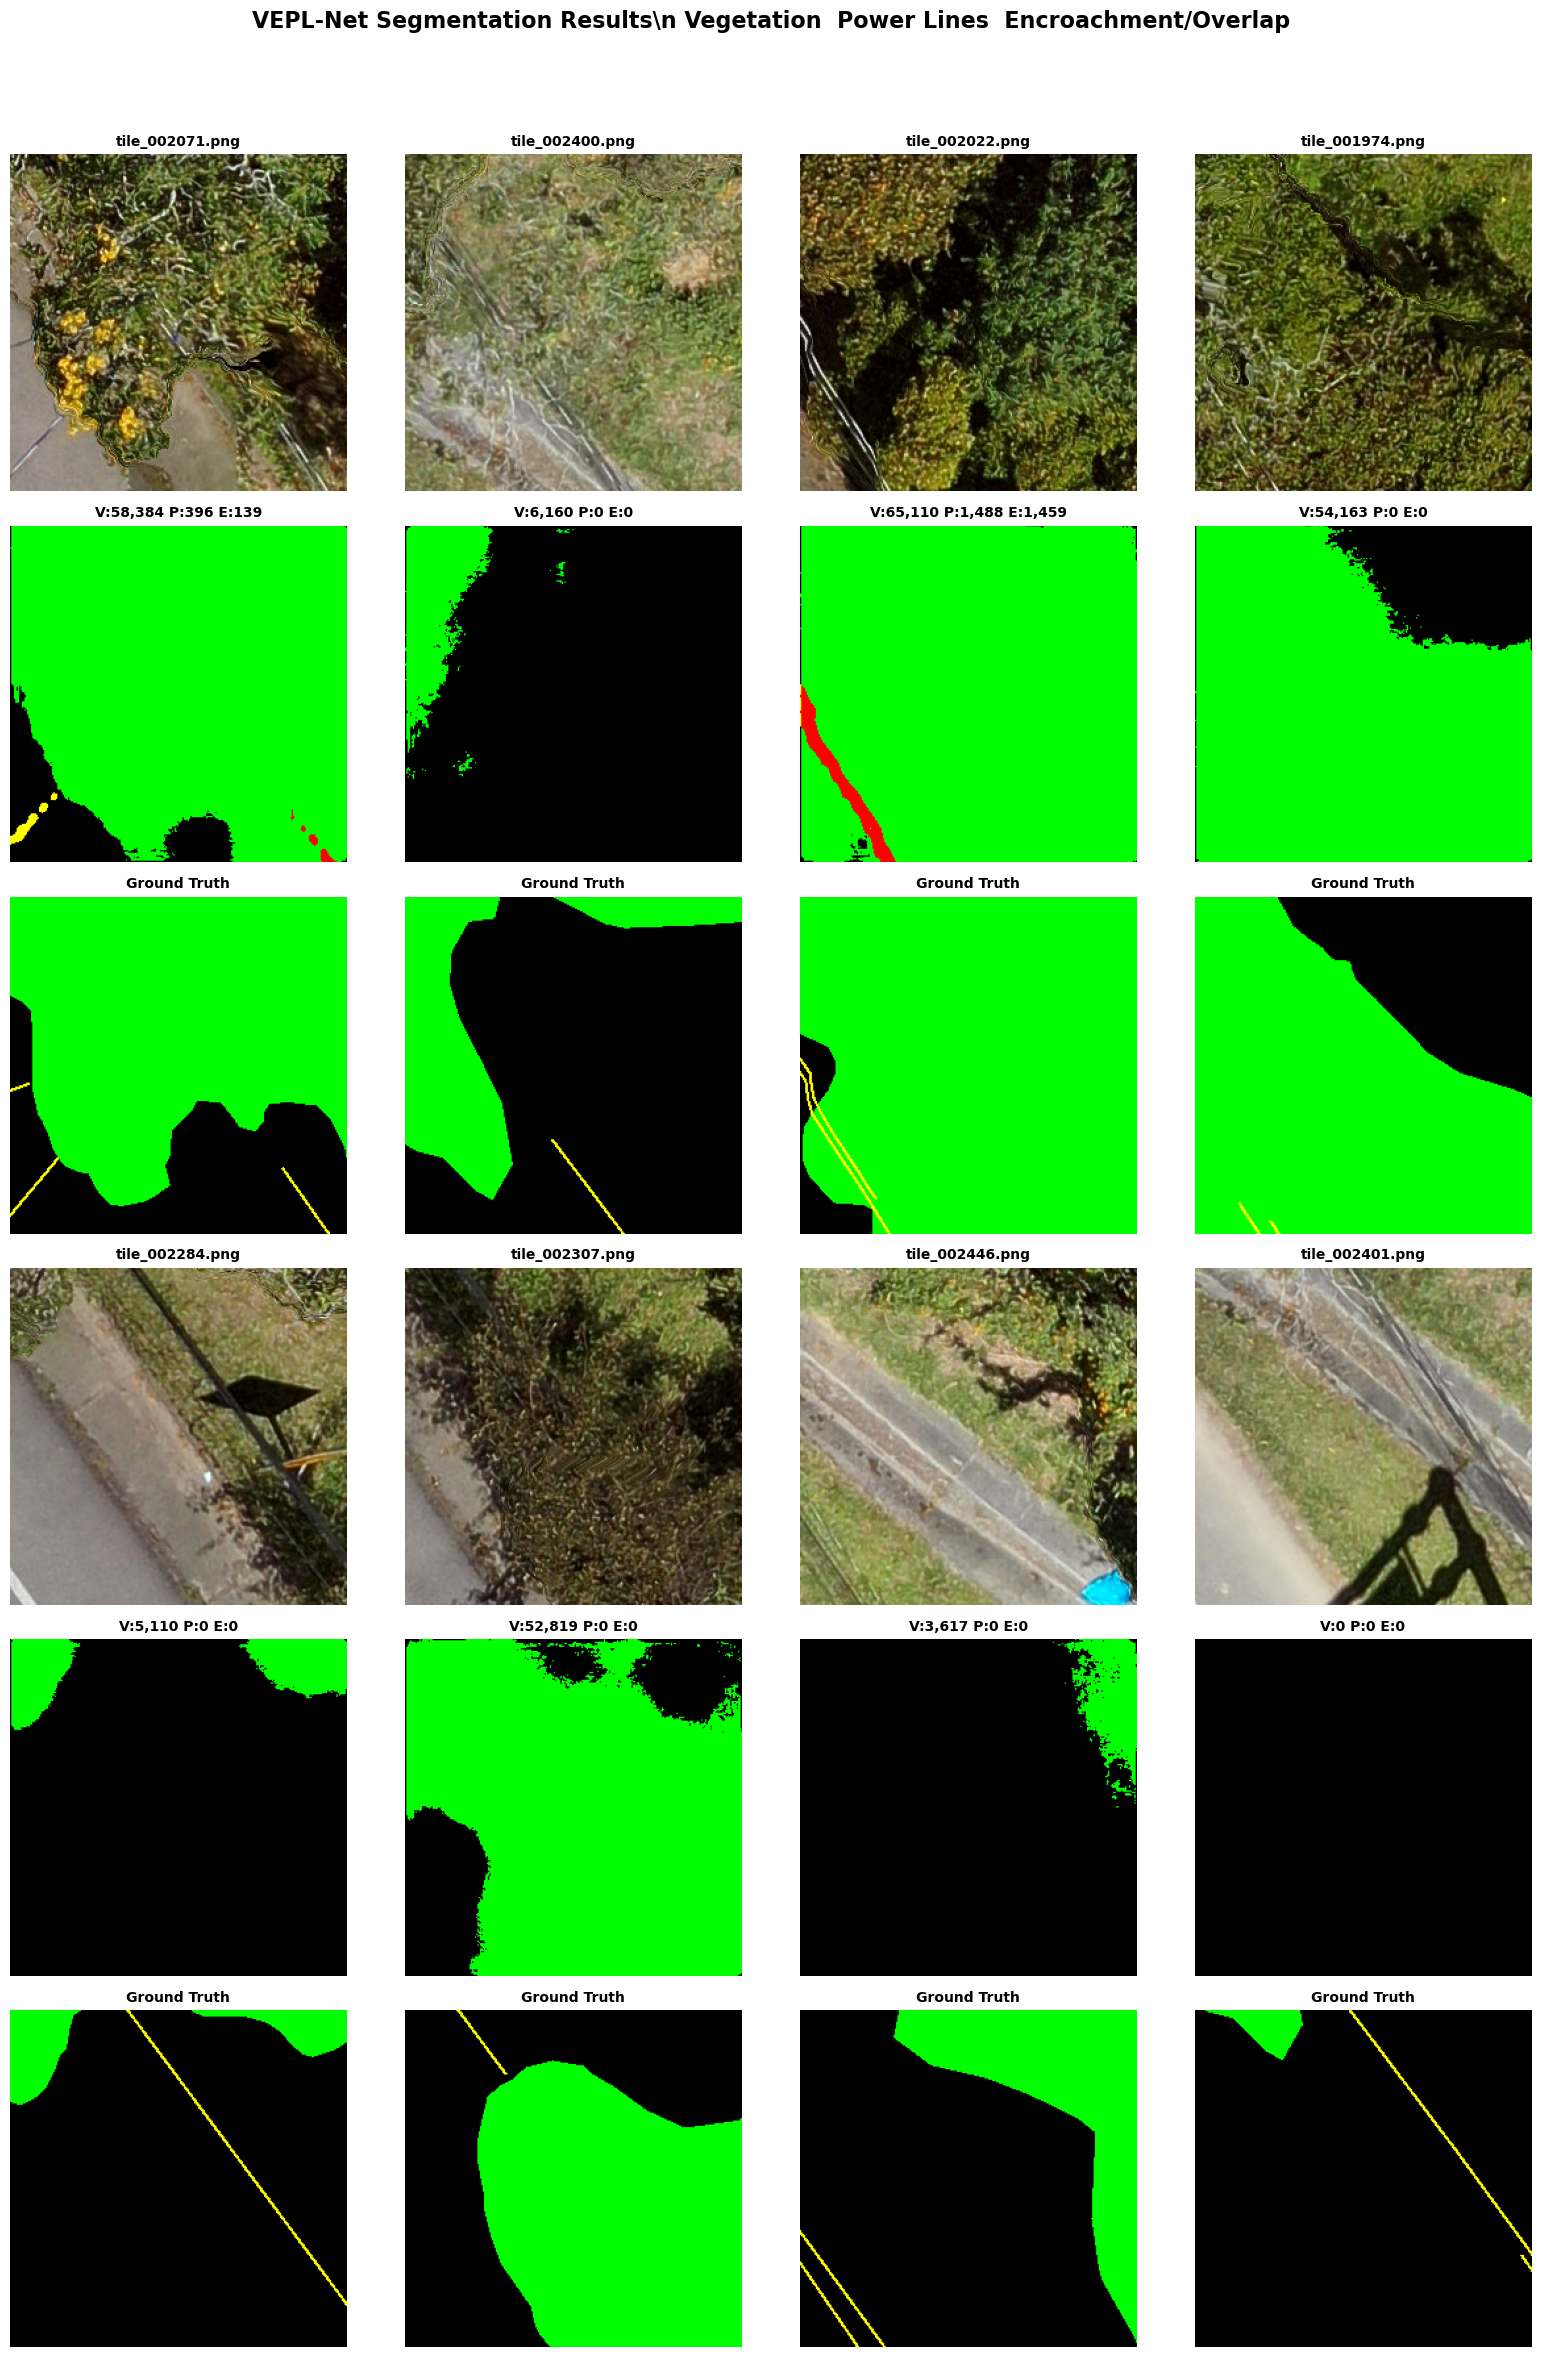

In [ ]:
import os
import random

# Dataset configuration
TOTAL_IMAGES = 2447
TEST_RATIO = 0.2
DATA_DIR = '../processed_data'

# Calculate test set range (last 20% of images)
train_size = int(TOTAL_IMAGES * (1 - TEST_RATIO))
test_start_idx = train_size
test_end_idx = TOTAL_IMAGES - 1

print(f"Total images: {TOTAL_IMAGES}")
print(f"Training images: 0 to {train_size - 1}")
print(f"Test images: {test_start_idx} to {test_end_idx}")
print(f"Test set size: {test_end_idx - test_start_idx + 1}")

def has_both_classes(mask_path, veg_threshold=50, pl_threshold=10):
    """
    Check if a mask contains both vegetation and power lines.
    
    Args:
        mask_path (str): Path to mask file
        veg_threshold (int): Minimum vegetation pixels required
        pl_threshold (int): Minimum power line pixels required
    
    Returns:
        tuple: (has_both, veg_pixels, pl_pixels)
    """
    if not os.path.exists(mask_path):
        return False, 0, 0
    
    # Load mask
    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
    if mask is None:
        return False, 0, 0
    
    # Convert BGR to RGB if needed
    if len(mask.shape) == 3:
        mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
    
    # Define class RGB values
    VEGETATION_RGB = (0, 255, 0)    # Green
    POWERLINE_RGB = (110, 110, 110) # Gray
    
    # Count pixels for each class using RGB values
    if len(mask.shape) == 3:
        vegetation_mask = np.all(mask == VEGETATION_RGB, axis=2)
        vegetation_pixels = np.sum(vegetation_mask)
        
        powerline_mask = np.all(mask == POWERLINE_RGB, axis=2)  
        powerline_pixels = np.sum(powerline_mask)
    else:
        # Fallback for grayscale masks
        vegetation_pixels = np.sum(mask == 255)  # Green -> ~255 in grayscale
        powerline_pixels = np.sum(mask == 110)   # Gray -> 110 in grayscale
    
    has_both = vegetation_pixels >= veg_threshold and powerline_pixels >= pl_threshold
    return has_both, vegetation_pixels, powerline_pixels

def get_random_test_images(num_images=8, require_both_classes=True):
    """
    Get random image paths from the test set, optionally filtering for images 
    that contain both vegetation and power lines.
    """
    test_indices = list(range(test_start_idx, test_end_idx + 1))
    
    if require_both_classes:
        print("Filtering for images with both vegetation and power lines...")
        valid_indices = []
        
        for idx in test_indices:
            mask_path = os.path.join(DATA_DIR, 'masks', f'tile_{idx:06d}.png')
            has_both, veg_px, pl_px = has_both_classes(mask_path)
            
            if has_both:
                valid_indices.append((idx, veg_px, pl_px))
        
        print(f"Found {len(valid_indices)} test images with both classes")
        
        if len(valid_indices) < num_images:
            print(f"Only {len(valid_indices)} images available with both classes")
            num_images = len(valid_indices)
        
        # FIXED: Use random selection instead of always taking the top images
        random.shuffle(valid_indices)  # Randomize the order
        selected_indices = [idx for idx, _, _ in valid_indices[:num_images]]
        
        print("Selected images with class pixel counts:")
        for i, (idx, veg_px, pl_px) in enumerate(valid_indices[:num_images]):
            print(f"  tile_{idx:06d}.png: VEG={veg_px:,}, PL={pl_px:,}")
    else:
        selected_indices = random.sample(test_indices, min(num_images, len(test_indices)))
    
    image_paths = []
    for idx in selected_indices:
        image_path = os.path.join(DATA_DIR, 'images', f'tile_{idx:06d}.png')
        if os.path.exists(image_path):
            image_paths.append(image_path)
        else:
            print(f"Warning: Image not found: {image_path}")
    
    return image_paths

def create_colored_segmentation(veg_mask, pl_mask, encroachment_mask, image_shape):
    """
    Create a colored segmentation visualization:
    - Vegetation: Green (0, 255, 0)
    - Power Lines: Yellow (255, 255, 0)  
    - Encroachment/Overlap: Red (255, 0, 0)
    """
    # Create RGB image
    colored_mask = np.zeros((image_shape[0], image_shape[1], 3), dtype=np.uint8)
    
    # Apply colors in order of priority (encroachment > power lines > vegetation)
    # Vegetation areas (green)
    vegetation_only = np.logical_and(veg_mask > 0.5, pl_mask <= 0.5)
    colored_mask[vegetation_only] = [0, 255, 0]  # Green
    
    # Power line areas (yellow)
    powerline_only = np.logical_and(pl_mask > 0.5, veg_mask <= 0.5)
    colored_mask[powerline_only] = [255, 255, 0]  # Yellow
    
    # Encroachment areas (red) - highest priority
    colored_mask[encroachment_mask > 0] = [255, 0, 0]  # Red
    
    return colored_mask

def predict_and_visualize_batch(image_paths):
    """
    Predict encroachment with simplified 3-row visualization:
    Row 1: Original image
    Row 2: Model predictions (Green=Vegetation, Yellow=Power Lines, Red=Overlap)
    Row 3: Ground truth segmentation (same color scheme)
    """
    num_images = len(image_paths)
    if num_images == 0:
        print("No valid images found!")
        return
    
    # Simple layout: 3 rows per image
    cols = min(4, num_images)  # Max 4 columns for readability
    rows_per_image = 3  # SIMPLIFIED to 3 rows
    total_rows = rows_per_image
    
    # If more than 4 images, create multiple rows of image sets
    if num_images > 4:
        sets = (num_images + 3) // 4  # Number of 4-image sets needed
        total_rows = rows_per_image * sets
        cols = 4
    
    print(f"Creating simplified visualization grid: {total_rows} rows x {cols} columns for {num_images} images")
    
    # Create the figure with proper size
    fig, axes = plt.subplots(total_rows, cols, figsize=(cols * 4, total_rows * 4))
    
    # Handle single image case
    if num_images == 1:
        axes = axes.reshape(-1, 1)
    elif total_rows == 3:  # Single row of images
        axes = axes.reshape(3, -1)
    
    for i, image_path in enumerate(image_paths):
        # Calculate position in grid
        set_idx = i // 4  # Which set of 4 images
        col = i % 4       # Column within the set
        row_offset = set_idx * rows_per_image
        
        try:
            # Load and preprocess image
            image_bgr = cv2.imread(image_path)
            if image_bgr is None:
                print(f"Could not load image: {image_path}")
                continue
                
            image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
            
            # Load corresponding ground truth mask
            image_name = os.path.basename(image_path)
            mask_path = os.path.join(DATA_DIR, 'masks', image_name)
            
            # Process with model
            augmented = transform(image=image_rgb)
            input_tensor = augmented['image'].unsqueeze(0).to(DEVICE)

            with torch.no_grad():
                # Get model predictions
                pred_veg = torch.sigmoid(veg_model(input_tensor))
                pred_pl = torch.sigmoid(pl_model(input_tensor))
                
                # Convert to numpy
                pred_veg_np = pred_veg.squeeze(0).squeeze(0).cpu().numpy()
                pred_pl_np = pred_pl.squeeze(0).squeeze(0).cpu().numpy()

            # Create encroachment mask (intersection)
            encroachment_mask = np.logical_and(pred_veg_np > 0.5, pred_pl_np > 0.5)
            
            # Create colored prediction visualization
            pred_colored = create_colored_segmentation(pred_veg_np, pred_pl_np, encroachment_mask, image_rgb.shape)
            
            # Load and process ground truth mask
            gt_colored = np.zeros_like(image_rgb)
            if os.path.exists(mask_path):
                gt_mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)
                if gt_mask is not None:
                    gt_mask = cv2.cvtColor(gt_mask, cv2.COLOR_BGR2RGB)
                    
                    # Create ground truth colored visualization
                    # Vegetation: Green pixels (0, 255, 0)
                    # Power lines: Gray pixels (110, 110, 110) -> convert to yellow
                    # Overlap: Check if both exist in same area -> red
                    
                    veg_gt = np.all(gt_mask == [0, 255, 0], axis=2)
                    pl_gt = np.all(gt_mask == [110, 110, 110], axis=2)
                    
                    # For ground truth, we don't have direct overlap info, so we'll show as separate
                    gt_colored[veg_gt] = [0, 255, 0]    # Green for vegetation
                    gt_colored[pl_gt] = [255, 255, 0]   # Yellow for power lines
            
            # Calculate statistics
            veg_pixels = np.sum(pred_veg_np > 0.5)
            pl_pixels = np.sum(pred_pl_np > 0.5)  
            encroach_pixels = np.sum(encroachment_mask)
            
            # Row 1: Original image - more concise title
            axes[row_offset + 0, col].imshow(image_rgb)
            axes[row_offset + 0, col].set_title(f"{image_name}", fontsize=10, fontweight='bold')
            axes[row_offset + 0, col].axis('off')
            
            # Row 2: Model predictions - more concise title
            axes[row_offset + 1, col].imshow(pred_colored)
            axes[row_offset + 1, col].set_title(f"V:{veg_pixels:,} P:{pl_pixels:,} E:{encroach_pixels:,}", 
                                              fontsize=10, fontweight='bold')
            axes[row_offset + 1, col].axis('off')
            
            # Row 3: Ground truth - more concise title
            axes[row_offset + 2, col].imshow(gt_colored)
            axes[row_offset + 2, col].set_title(f"Ground Truth", 
                                              fontsize=10, fontweight='bold')
            axes[row_offset + 2, col].axis('off')
            
            print(f"Processed {image_name}: VEG={veg_pixels:,}, PL={pl_pixels:,}, ENCROACH={encroach_pixels:,}")
            
        except Exception as e:
            print(f"Error processing {image_path}: {str(e)}")
            continue
    
    # Hide unused subplots properly
    total_subplots = total_rows * cols
    images_shown = min(num_images, total_subplots // 3)  # 3 rows per image
    
    for i in range(images_shown, total_subplots // 3):
        col = i % 4
        set_idx = i // 4
        row_offset = set_idx * rows_per_image
        
        for row in range(3):  # 3 rows per image
            if row_offset + row < total_rows:
                axes[row_offset + row, col].axis('off')
    
    # Add suptitle first, then adjust layout
    plt.suptitle('VEPL-Net Segmentation Results\\n Vegetation  Power Lines  Encroachment/Overlap',
                 fontsize=16, fontweight='bold', y=0.98)
    
    # Use constrained layout to prevent overlap
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

# Get test images with both vegetation and power lines
print("Selecting test images with both vegetation and power lines...")
filtered_test_paths = get_random_test_images(num_images=8, require_both_classes=True)
print(f"Selected {len(filtered_test_paths)} test images with both classes")

if filtered_test_paths:
    predict_and_visualize_batch(filtered_test_paths)
else:
    print("No test images found with both vegetation and power lines!")
    print("Falling back to random test images...")
    random_test_paths = get_random_test_images(num_images=8, require_both_classes=False)
    if random_test_paths:
        predict_and_visualize_batch(random_test_paths)